# Estimador

Dado el vector de datos ${\bf x}_k \in R^{2\times 1}$ y matriz de transición $F_k$ relacionadas de la siguiente manera:

$$ {\bf x}_k =  F_k  {\bf x}_{k-1} +   {\bf w}_{k-1}  $$

con $${\bf x}_k = [x, x', x'', y, y', y'']^T $$
siendo ${\bf w}_{k}\sim \mathcal{N}({\bf 0}, \sigma^2_w I_2) $ y  ${\bf w}_{k} \in R^{2\times 1}$ el vector que representa ruido en el sistema.

Además, las observaciones están dadas por:

$${\bf z}_k = H_k {\bf x}_k  + {\bf v}_k  $$




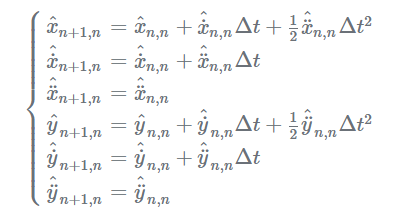


\begin{equation}
F_{k}=\left[\begin{array}{cccccc}
1 & \Delta t& 0.5\Delta t^2 & 0 & 0 & 0\\
0 & 1       & \Delta t   & 0 & 0 & 0\\
0 & 0 & 1 & 0 & 0 & 0\\
0 & 0 & 0 & 1 & \Delta t & 0.5\Delta t^2\\
0 & 0 & 0 & 0 & 1 & \Delta t\\
0 & 0 & 0 & 0 & 0 & 1
\end{array}\right]
\end{equation}

\begin{equation}
H_{k}=\left[\begin{array}{cccccc}
1 & 0 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 1 & 0 & 0
\end{array}\right]
\end{equation}


In [29]:
import numpy as np
import matplotlib.pyplot as plt


In [30]:
# Generación de N=1000 muestras de la señal x(n)
N=100
Ts = 0.2 # delta_t
t = Ts*np.arange(N)
x = np.zeros((6, N))
z = np.zeros((2, N))
S2_w = 0.5*np.eye(6) 
S2_v = 0.2*np.eye(2) 

Ta = 0.5*(Ts**2)
F = np.array([[1, Ts, Ta, 0,  0,  0],
              [0,  1, Ts, 0,  0,  0],
              [0,  0, 1,  0,  0,  0],
              [0,  0, 0,  1,  Ts, Ta],
              [0,  0, 0,  0,  1,  Ts], 
              [0,  0, 0,  0,  0,  1]])

H = np.array([[1, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0]])

for k in range(1, N):
  wk = np.linalg.cholesky(S2_w)@np.random.randn(6,1)
  xk_1 = np.reshape(x[:,k-1], (6,1))
  xk=F@xk_1 + wk
  x[:,k] = xk.ravel()
  vk = np.linalg.cholesky(S2_v)@np.random.randn(2,1)
  zk = H@xk + vk
  z[:, k] = zk.ravel()

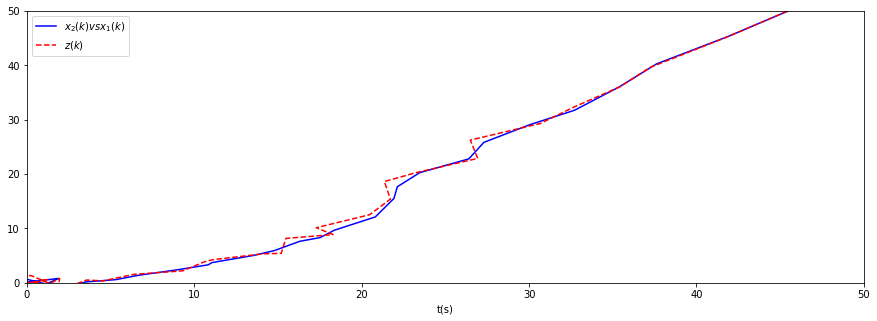

In [36]:
plt.figure(figsize=(15, 5))
plt.plot(x[0, :], x[3, :],'b-' , label = '$x_2(k) vs x_1(k)$')
plt.plot(z[0, :], z[1, :],'r--' , label = '$z(k)$')
plt.xlabel('t(s)')
plt.axis([0,50, 0, 50])
plt.legend()

## Implementación del algoritmo LMS

In [37]:
def get_x_kalman(z,F,  H, P,  B=0, u = 0, Q=0, R=0):
  Dz, N = z.shape
  D = F.shape[1]
  N = z.shape[1]
  x_est = np.zeros((D, N))
  #
  FT = np.transpose(F)
  HT = np.transpose(H)
  #initial conditions
  x_k1_k1 = np.zeros((D,1))   #x_{k-1|k-1}

  for k in range(1, N):
    # prior estimations
    xk_k1 = F@x_k1_k1 + B*u   #x_{k|k-1}
    P  = F@P@FT + Q           #P_{k|k-1}
    zk = np.reshape(z[:, k], (Dz,1))
    yk = zk - H@xk_k1
    Sk = H@P@HT + R
    # Kalman Gain
    K = P@HT@np.linalg.inv(Sk )
    
    # Porsterior
    xk  = xk_k1 + K@yk
    P  = (np.eye(D) - K@H)@P
    yk = zk - H@xk
    x_k1_k1 = xk
    #save results
    x_est[:,k] = xk.ravel()
  return x_est


In [38]:
x_est = get_x_kalman(z,F,  H, P=np.eye(6), Q=S2_w, R=S2_v )

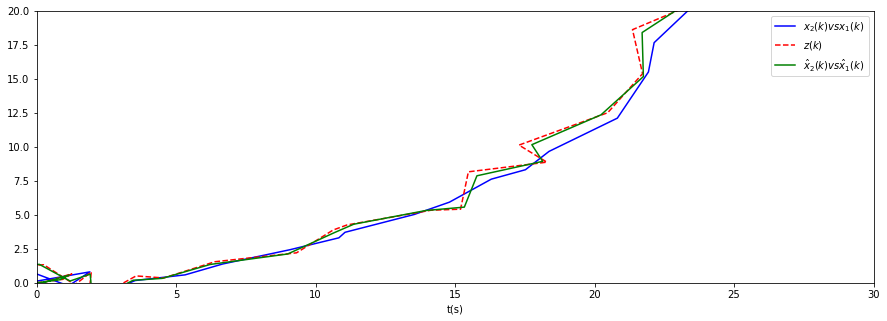

In [43]:
plt.figure(figsize=(15, 5))
plt.plot(x[0, :], x[3, :],'b-' , label = '$x_2(k) vs x_1(k)$')
plt.plot(z[0, :], z[1, :],'r--' , label = '$z(k)$')
plt.plot(x_est[0, :], x_est[3, :],'g-' , label = '$\hat{x}_2(k) vs \hat{x}_1(k)$')

plt.xlabel('t(s)')
plt.axis([0, 30, 0, 20])
plt.legend()